## Tarea 02 Física Computacional III
***Método del factor integrante-Pseudo-espectral***

**Fernanda Mella A**

#### 1. Aplique el método del factor integrante para integrar numéricamente la ecuación de Korteweg-de Vries descrita en la forma

$u_t = uu_x - u_{xxx}$ **(1)**

donde $x \in [-L/2, L/2]$, $L = 2\pi$ y se consideran condiciones de borde periódicas. La función inicial está dada por: 

$u(0,x) = 3A^2 \text{sech}^2(A(x+2)/2) +3B^2 \text{sech}(B(x+1)/2) $

**a. Escriba una breve reseña histórica sobre esta ecuación, sus autores, qué tipo de objeto matemático describe y cómo se observó la primera vez**

La ecuación de Korteweg-de Vries es una ecuación diferencial parcial no lineal que describe la evolución de ondas en medios dispersivos y no lineales. Tiene la forma: 

$u_t = uu_x - u_{xxx}$ 

Donde $u(x,t)$ representa la altura de la onda en la posición *x* y tiempo *t*, $uu_x$ será el término no lineal que capturará interacciones complejas y $u_{xxx}$ será el término dispersivo, que modelará la tendencia de las ondas a dispersarse.


En 1877 Joseph Valentin Boussinesq desarrolló ecuaciones para ondas no lineales, entregando las bases de lo que se iba a convertir en la ecuación de Korteweg-de Vries. Aun así el trabajo definitivo fue realizado por Diederik Korteweg y Gustav de Vries en 1895 en su trabajo, titulado *"On the Change of Form of Long Waves Advancing in a Rectangular Canal, and on a New Type of Long Stationary Waves"*. Ellos no sólo dedujeron la forma estándar de la ecuación sino que resolvió el problema abierto por Boussinesq al proponer la solución explícita de la onda solitaria: **el solitón**. 

Korteweg y de Vries tuvieron inspiración de John Scott Russell, quien en 1834 mientras estaba en el Union Canal que conecta Edimburgo con Forth-Clyde, observó la formación de una ola de gran amplitud generada por la parada repentina de una barcaza. Siguió esta ola a caballo durante varios kilómetros y descubrió que su forma y velocidad permanecían sin cambios durante su propagación. La onda que describiría este proceso el la llamaría *onda de traslación*, pero al día de hoy se conoce como **solitón**. Aun así, en ese tiempo la física-matemática de la época no podía explicarla. Por tanto, tras décadas de estudio, investigación y debate Korteweg y de Vries derivaron su ecuación para modelar estas ondas. 

Por lo tanto, la ecuación de Korteweg y de Vries describe a un solitón. Al día de hoy, esta ecuación es utilizada en diversas áreas de la física como: oceanografía, física de plasmas, óptica no lineal y teoría de cuerdas. Demostrando como fenómenos naturales, tales como observar una onda en el agua, puede encerrar estructuras matemáticas complejas que se podrán utilizar en diversas áreas. 

**b. Muestre la forma que toma la ecuación anterior al aplicar el método del factor integrante en el espacio espectral.**

A partir de la ecuación (1) diremos que el **operador lineal** será: $\mathcal{L}u = -u_{xxx}$. Y el operador **no lineal** será: $\mathcal{N}u = -uu_x$ 

Ahora, aplicamos la Transformada de Fourier a lo largo de $x$ a la ecuación **(1)**. Considerando a:

* $\mathcal{F}[u_t] = \hat{u}_t$
* $\mathcal{F}[-u_{xxx}] = -(i\omega)^3\hat{u} = i\omega^3\hat{u}$

Por otro lado reescribimos $uu_x$. Considerando: 

$\frac{\partial (u^2)}{\partial x} = 2uu_x$

Por lo tanto $uu_x = \frac{1}{2}\frac{\partial (u^2)}{\partial x}$ y su Transformada de Fourier: 

* $\mathcal{F}[\frac{1}{2}\frac{\partial (u^2)}{\partial x}] = (i\omega)\hat{u^2}$ 

Así, reescribimos (1): 

$\hat{u}_t = (i\omega)\hat{u^2} + i\omega^3\hat{u}$ **(2)**

Definamos a $\lambda = i\omega^3$. Tal que podamos seguir desarrollando **(2)**:

$\hat{u}_t = (i\omega)\hat{u^2} +  \lambda\hat{u}$

$e^{-\lambda t}\hat{u}_t = (i\omega)e^{-\lambda t}\hat{u^2} +  \lambda e^{-\lambda t}\hat{u}$ **(3)**

Por otro lado, consideremos: 

$\frac{d(e^{-\lambda t}\hat{u})}{dt} = e^{-\lambda t}\hat{u}_t -\lambda e^{-\lambda t}\hat{u}$ 

Reordenando obtenemos: $e^{-\lambda t}\hat{u}_t = \frac{d(e^{-\lambda t}\hat{u})}{dt} + \lambda e^{-\lambda t}\hat{u}$. Reemplazando en **(3)**: 

$\frac{d(e^{-\lambda t}\hat{u})}{dt} + \lambda e^{-\lambda t}\hat{u} = (i\omega)e^{-\lambda t}\hat{u^2} +  \lambda e^{-\lambda t}\hat{u}$

$\frac{d(e^{-\lambda t}\hat{u})}{dt} = (i\omega)e^{-\lambda t}\hat{u^2}$ **(4)**

Definamos a $\hat{U} = e^{-\lambda t}\hat{u}$ e introduzcamoslo en **(4)**: 

$\hat{U}_t = (i\omega)e^{-\lambda t}\hat{u^2}$ **(5)**

Y considerando a $u = \mathcal{F}^{-1}[\hat{u}] = \mathcal{F}^{-1}[e^{\lambda t}\hat{U}]$ e introduciendolo en **(5)**: 

$\hat{U}_t = (i\omega)e^{-\lambda t}\mathcal{F}[(\mathcal{F}[e^{\lambda t}\hat{U}])^2]$





Que será la forma que tomará la ecuación al deshacernos del término no lineal utilizando el método de factor integrante. 


**c. Utilice el integrador de Runge-Kutta de cuarto orden tradicional y muestre que el algoritmo toma la forma del código escrito en Matlab (por Lloyd N. Trefethen) incluido en la carpeta ProblemasStiff. Resolver entonces el problema de ese documento utilizando un programa escrito en Julia y reproducir la figura correspondiente, pero con la técnica vista en clases para figuras 3D en colores y con barra adyacente. Nota, para el código en Julia utilice lo visto en clases y mejore la programación evitando cómputos innecesarios como los que aparecen en el documento indicado (¿cuáles son?).** 

Para resolver la ecuación KdV se utilizó el siguiente código: 

In [1]:
using FFTW, PyPlot

In [ ]:
function KdV(t,Uhat,w)   #define el KdV con el método factor integrante 
    FFTW.set_num_threads(2)
    
    Uhat_t = -0.5im.*w.*exp.(-1im*w.^3*t).*fft(real(ifft(exp.(1im*w.^3*t).*Uhat)).^2)
    return Uhat_t
end

function wavevector(L,Nx)
    knx=collect(1:Nx).-(Nx/2+1)
    kx=2pi*fftshift(knx)/L
end


function rk4(t,Uhat,w) #método runge-kutta tradicional
    n=length(Uhat)
    hw1, hw2, hw3, hw4 =zeros(n), zeros(n), zeros(n), zeros(n)
    hw1=dt*KdV(t,Uhat,w)
    hw2=dt*KdV(t+dt/2,Uhat+hw1/2,w)
    hw3=dt*KdV(t+dt/2,Uhat+hw2/2,w)
    hw4=dt*KdV(t+dt,Uhat+hw3,w)
    Uhat+= (hw1.+ 2(hw2.+hw3) .+hw4)/6
    return Uhat
end

#Discretización del espacio
N= 256
L= 2pi
dx=L/N
x=range(-L/2,L/2,length=N+1)[1:end-1]
w=wavevector(L,N)

#Tiempo
t_f= 0.006
dt= 0.426/N^2
Nt=round(Int,t_f/dt)
t= 0.0

#Condiciones Iniciales
A= 25
B= 16
u0=@. 3A^2*sech(0.5*(A*(x+2)))^2 + 3B^2*sech(0.5*(B*(x+1)))^2
Uhat=copy(fft(u0))
warr=zeros(N,Nt)

#evolucion en el tiempo de la solucion desde la condicion inicial 
@time for i in 1:Nt
    warr[:,i] =real(ifft(exp.(t.*1im*w.^3).*Uhat))
    t=i*dt
    Uhat = rk4(t,Uhat,w)
end;

#figura
pygui(true)  
figure(figsize=(10, 6))

imshow(warr', aspect="auto", origin="lower", 
       extent=[-L/2, L/2, 0, t_f], interpolation="bilinear", 
       cmap=ColorMap("viridis")) 

ylabel(L"$t$", fontsize=12)
xlabel(L"$x$", fontsize=12)
title("Solución KdV", fontsize=14)
colorbar(label=L"$u(x,t)$") 

show()

  0.585062 seconds (587.79 k allocations: 253.977 MiB, 8.96% gc time, 29.82% compilation time)



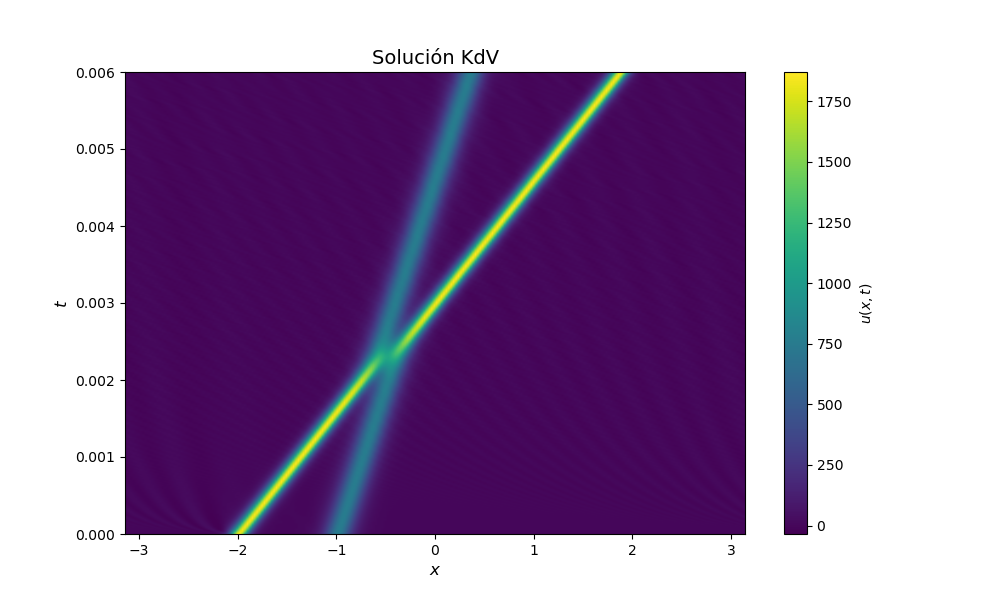

Además, vemos que al momento de hacer el código vemos que nos saltamos o editamos partes de los códigos originales. Por ejemplo, en vez de definir variables auxiliares $E$ y $E^2$ como en el código del Programa 27, usamos directamente la definición de la exponencial dentro de los cálculos. También, cambia el almacenamiento de datos, ya que el código MATLAB almacena solo ciertos instantes temporales (determinados por nplt), mientras que nuestro código en Julia almacena la solución completa en cada paso temporal en la matriz warr. 
